# Simple Linear Regression From Scratch

Simple linear regression fits a straight line through the data to predict one number (y) from one input (x).

$$y = mx + b$$

* **m** is the slope: how much y changes when x goes up by 1.
* **b** is the intercept: the value of y when x is 0.

The best line is the one that makes the squared errors between the real y and the predicted y as small as possible. This is called ordinary least squares. Solving it gives two formulas:

$$m = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sum (x_i - \bar{x})^2}$$

$$b = \bar{y} - m\bar{x}$$

The top part of `m` is the covariance idea from our statistics notebooks, and the bottom part is the variance idea. We will code these formulas ourselves, then check them against scikit-learn.

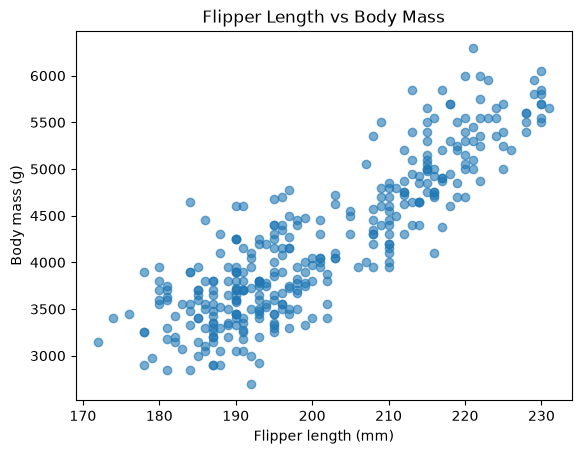

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

penguins = sns.load_dataset("penguins").dropna(subset=['flipper_length_mm', 'body_mass_g'])

X = penguins[['flipper_length_mm']]
y = penguins['body_mass_g']

plt.scatter(X, y, alpha=0.6)
plt.xlabel('Flipper length (mm)')
plt.ylabel('Body mass (g)')
plt.title('Flipper Length vs Body Mass')
plt.show()

## Choosing the Data

We use the penguins dataset. The question is: can we predict a penguin's body mass from its flipper length? The scatter plot shows the points rising in a fairly straight band, so a straight line is a good fit here.

In [5]:
class ManualLR:
    def __init__(self):
        self.m = 0  # slope
        self.b = 0  # intercept

    def fit(self, X_train, y_train):
        X_train = np.array(X_train).flatten()
        y_train = np.array(y_train).flatten()

        x_mean = X_train.mean()
        y_mean = y_train.mean()

        numerator = np.sum((X_train - x_mean) * (y_train - y_mean))
        denominator = np.sum((X_train - x_mean) ** 2)

        self.m = numerator / denominator
        self.b = y_mean - (self.m * x_mean)

    def predict(self, X_test):
        X_test = np.array(X_test).flatten()
        return (self.m * X_test) + self.b

## Train Test Split

We keep 80% of the penguins for training and 20% for testing. The line is learned from the training rows only, and the test rows show how well it works on penguins it has never seen.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (273, 1)
Test size: (69, 1)


## Fitting Our Own Model

Now we use the class we wrote. `fit` calculates the slope and the intercept from the training data using the two formulas.

In [7]:
manual_model = ManualLR()
manual_model.fit(X_train, y_train)

print("Slope (m):", manual_model.m)
print("Intercept (b):", manual_model.b)

Slope (m): 48.829682818993014
Intercept (b): -5614.067120606901


## Checking Against scikit-learn

If our formulas are right, scikit-learn should give the same slope and intercept.

In [8]:
from sklearn.linear_model import LinearRegression

sk_model = LinearRegression()
sk_model.fit(X_train, y_train)

print("Our slope:      ", manual_model.m)
print("sklearn slope:  ", sk_model.coef_[0])
print()
print("Our intercept:     ", manual_model.b)
print("sklearn intercept: ", sk_model.intercept_)

Our slope:       48.829682818993014
sklearn slope:   48.82968281899301

Our intercept:      -5614.067120606901
sklearn intercept:  -5614.067120606899


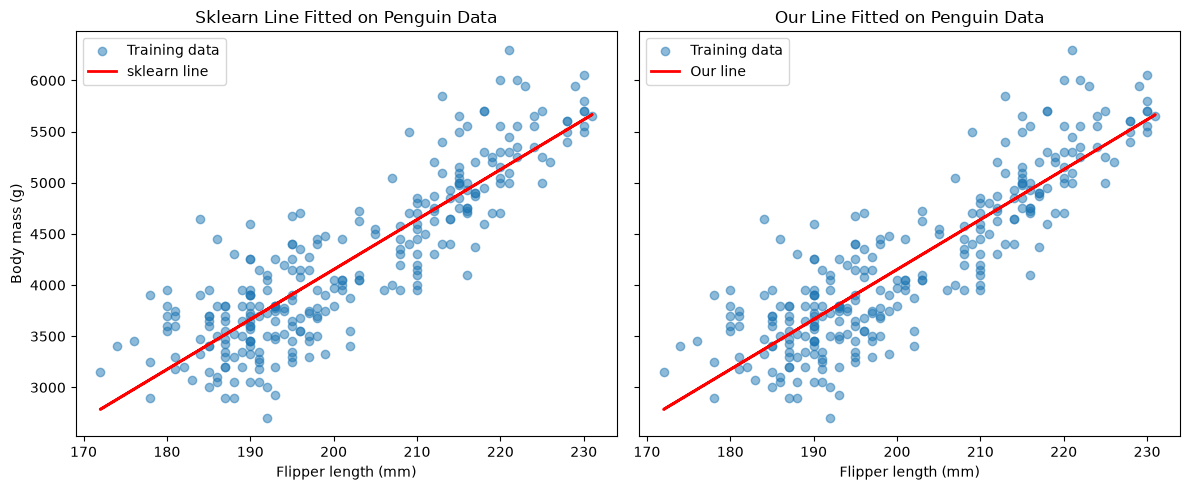

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# sklearn line
sk_line = sk_model.predict(X_train)
axes[0].scatter(X_train, y_train, alpha=0.5, label='Training data')
axes[0].plot(X_train, sk_line, color='red', linewidth=2, label='sklearn line')
axes[0].set_title('Sklearn Line Fitted on Penguin Data')
axes[0].set_xlabel('Flipper length (mm)')
axes[0].set_ylabel('Body mass (g)')
axes[0].legend()

# our line
our_line = manual_model.predict(X_train)
axes[1].scatter(X_train, y_train, alpha=0.5, label='Training data')
axes[1].plot(X_train, our_line, color='red', linewidth=2, label='Our line')
axes[1].set_title('Our Line Fitted on Penguin Data')
axes[1].set_xlabel('Flipper length (mm)')
axes[1].legend()

plt.tight_layout()
plt.show()

Both plots show the same line. Our own formulas and scikit-learn found the same slope and intercept, so the lines sit exactly on top of each other.

To confirm it with numbers and not just by eye, we can check that every prediction is the same.

In [16]:
print("All predictions match:", np.allclose(sk_model.predict(X_test), manual_model.predict(X_test)))

All predictions match: True


np.allclose ignores the tiny floating point differences.

## Measuring the Error

A line can look good on a plot and still make big mistakes. To measure it, we compare the real body mass with the predicted body mass on the test set. The gap between them for each penguin is called the error (or residual).

We use four common metrics:

* **MAE (mean absolute error):** the average size of the errors, ignoring direction. It is in grams, so it is easy to read.
* **MSE (mean squared error):** the average of the squared errors. Squaring punishes big mistakes more, and it is the quantity the least squares line minimizes.
* **RMSE (root mean squared error):** the square root of MSE. It brings the units back to grams.
* **R² score:** how much of the variation in body mass our line explains.

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

### How to Read R²

* **R² = 1:** the model is a perfect fit and explains 100% of the variance.
* **R² = 0:** the model does no better than always guessing the mean of the target, so the input gives no predictive power.
* **Negative R²:** the model does worse than the mean baseline. This often means the chosen algorithm does not suit the data.

In [17]:
y_pred = manual_model.predict(X_test)
y_true = np.array(y_test)

errors = y_true - y_pred

mae = np.mean(np.abs(errors))
mse = np.mean(errors ** 2)
rmse = np.sqrt(mse)

ss_res = np.sum(errors ** 2)
ss_tot = np.sum((y_true - y_true.mean()) ** 2)
r2 = 1 - ss_res / ss_tot

print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2:   {r2:.4f}")

MAE:  315.86
MSE:  144928.59
RMSE: 380.69
R2:   0.7820


In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print(f"MAE:  {mean_absolute_error(y_test, y_pred):.2f}")
print(f"MSE:  {mean_squared_error(y_test, y_pred):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")
print(f"R2:   {r2_score(y_test, y_pred):.4f}")

MAE:  315.86
MSE:  144928.59
RMSE: 380.69
R2:   0.7820
